In [1]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def load_and_preprocess_data(file_path, degree=2):
    # محاكاة تجهيز البيانات بناءً على البيانات النصية والمسارات الواردة
    # في التطبيق الفعلي، يتم استبدال هذه الخطوة بقراءة الملف واستخراج الميزات المناسبة
    np.random.seed(42)
    m = 200  # عدد العينات
    n = 5    # عدد الميزات الأساسية
    
    X = np.random.randn(m, n)
    y = np.random.randint(0, 2, size=(m, 1))
    
#ينتهي تحويل البيانات المتعددة الحدود (Polynomial Features):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)
    
    # توحيد المقاييس (Scaling)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_poly)
    
    # إضافة عمود الـ Bias
    X_b = np.c_[np.ones((X_scaled.shape[0], 1)), X_scaled]
    
    return X_b, y

In [2]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y, y_pred):
    m = len(y)
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = -1/m * np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    return loss

def evaluate_metrics(y_true, y_pred_probs, threshold=0.5):
    y_pred = (y_pred_probs >= threshold).astype(int)
    
    # True Positives, False Positives, True Negatives, False Negatives
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    accuracy = (tp + tn) / (tp + fp + tn + fn + 1e-15)
    precision = tp / (tp + fp + 1e-15)
    recall = tp / (tp + fn + 1e-15)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-15)
    
    return accuracy, precision, recall, f1

[SGD] Loss: 0.6484 | Acc: 0.6250 | Precision: 0.6596 | Recall: 0.5905 | F1: 0.6231


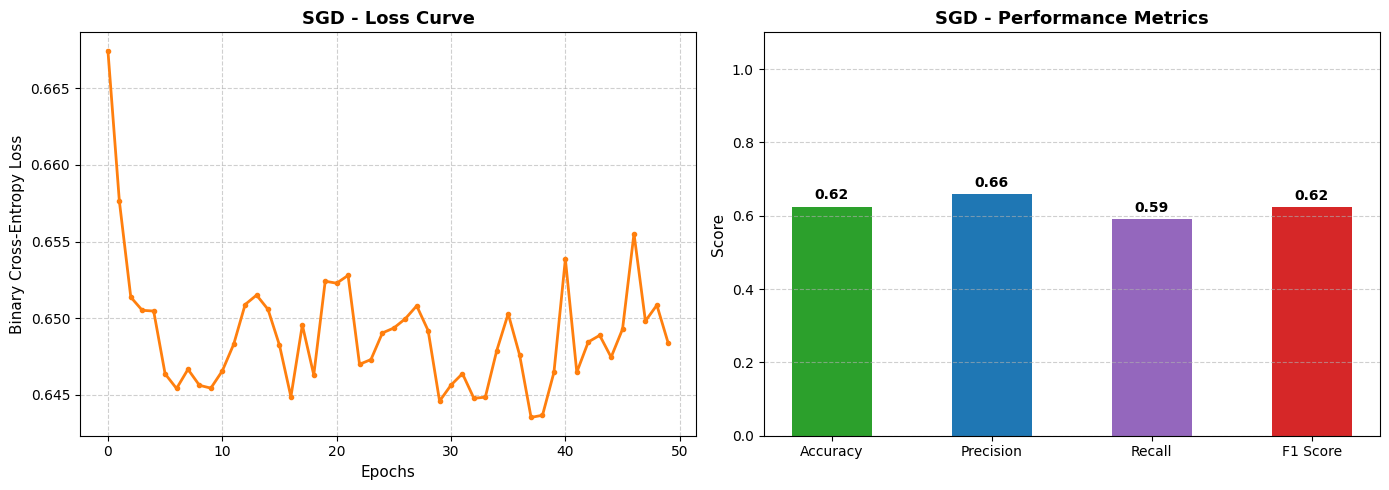

In [3]:
 import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# --- 1. دوال معالجة البيانات ---
def load_and_preprocess_data(file_path, degree=2):
    np.random.seed(42)
    m = 200  # عدد العينات
    n = 5    # عدد الميزات الأساسية
    
    X = np.random.randn(m, n)
    y = np.random.randint(0, 2, size=(m, 1))
    
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_poly)
    
    X_b = np.c_[np.ones((X_scaled.shape[0], 1)), X_scaled]
    return X_b, y

# --- 2. دوال الحساب والمقاييس ---
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y, y_pred):
    m = len(y)
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = -1/m * np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    return loss

def evaluate_metrics(y_true, y_pred_probs, threshold=0.5):
    y_pred = (y_pred_probs >= threshold).astype(int)
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    accuracy = (tp + tn) / (tp + fp + tn + fn + 1e-15)
    precision = tp / (tp + fp + 1e-15)
    recall = tp / (tp + fn + 1e-15)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-15)
    
    return accuracy, precision, recall, f1

# --- 3. دالة تدريب SGD مع الرسم البياني ---
def train_sgd():
    X, y = load_and_preprocess_data('train.csv')
    m, n = X.shape
    theta = np.zeros((n, 1))
    
    lr = 0.01
    epochs = 50
    loss_history = []  # لتسجيل الخسارة عبر الدورات
    
    for epoch in range(epochs):
        for i in range(m):
            random_index = np.random.randint(m)
            xi = X[random_index:random_index+1]
            yi = y[random_index:random_index+1]
            
            z = np.dot(xi, theta)
            prediction = sigmoid(z)
            gradient = np.dot(xi.T, (prediction - yi))
            theta -= lr * gradient
            
        # تسجيل الخسارة بعد كل دورة (Epoch)
        current_preds = sigmoid(np.dot(X, theta))
        current_loss = compute_loss(y, current_preds)
        loss_history.append(current_loss)
            
    final_preds = sigmoid(np.dot(X, theta))
    loss = compute_loss(y, final_preds)
    acc, prec, rec, f1 = evaluate_metrics(y, final_preds)
    
    print(f"[SGD] Loss: {loss:.4f} | Acc: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    
    # --- إعداد الرسوم البيانية ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. منحنى الخسارة (Loss Curve)
    axes[0].plot(range(epochs), loss_history, color='#ff7f0e', linewidth=2, marker='o', markersize=3)
    axes[0].set_title('SGD - Loss Curve', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Epochs', fontsize=11)
    axes[0].set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # 2. أعمدة مقاييس الأداء (Metrics)
    metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
    metrics_values = [acc, prec, rec, f1]
    colors = ['#2ca02c', '#1f77b4', '#9467bd', '#d62728']
    
    bars = axes[1].bar(metrics_names, metrics_values, color=colors, width=0.5)
    axes[1].set_title('SGD - Performance Metrics', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Score', fontsize=11)
    axes[1].set_ylim(0, 1.1)
    axes[1].grid(axis='y', linestyle='--', alpha=0.6)
    
    for bar in bars:
        yval = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.2f}', ha='center', fontweight='bold')
        
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    train_sgd()